# 28 · 近似索引的召回、候选与延迟

索引加速的本质是少看文档；代价可能是把正确文档在打分之前就丢掉。本章复用已有推荐课程的kmeans/partition_retrieval，不另写一套向量引擎。

**先预测**：探测2/12簇是否一定比12/12快6倍？精确近邻一致率与业务Recall是否是同一个指标？

本章固定40个测试查询做已见测试上的机制诊断，完整5,183文档；参数扫面用于观察取舍，不据此修改原正式run。

**学习导航：** [上一章](27_Search_Semantic.ipynb) · [下一章](29_Search_Fusion_Ranking.ipynb) · [综合实验](17_Search_Experiments.ipynb)

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if not (root / 'reclab').exists(): root = root.parent
os.chdir(root); sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reclab.search_lessons import context, query_vectors, score_query, labels
from reclab.search import BM25, rrf
from reclab.retrieval import topk, metrics
ctx = context()
print('Shared search run:', ctx['receipt']['run_id'])

Shared search run: 20261030T124927-d1467622


## 1. 精确检索先作为参照

精确检索计算所有文档与查询的点积；归一化后可以用欧氏距离路由到簇，再对候选精排。当前实现是教学粗索引，未用FAISS/HNSW/PQ，不代表生产ANN的性能。

聚类输出12×384中心和5,183个簇标签。先检查每篇文档恰好属于一簇，再看簇是否均匀。

centers / assignment: (12, 384) (5183,)


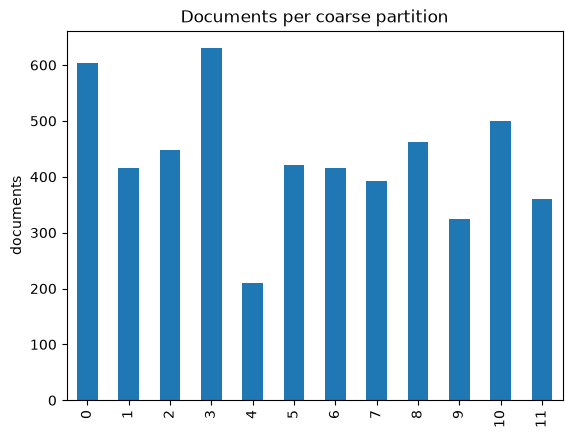

In [2]:
from reclab.learning.retrieval import kmeans, partition_retrieval
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=4): centers,assignment=kmeans(ctx['vectors'],clusters=12,seed=42)
counts=np.bincount(assignment,minlength=12)
assert counts.sum()==len(ctx['corpus'])
print('centers / assignment:',centers.shape,assignment.shape)
pd.Series(counts).plot.bar(title='Documents per coarse partition',ylabel='documents');plt.show()

## 2. 只改探测簇数

固定向量、簇中心、查询和排序规则，只变probes=1/2/4/12。报告两种召回：与精确前10交集比例反映近似误差；qrels Recall@10反映任务效果。它们不能互相替代。

计时只覆盖路由+候选打分+排序，不包含查询编码、模型加载、构建索引或HTTP，因此不能直接与第17章端到端延迟列相减。

In [3]:
from reclab.search_lessons import coarse_sweep
qids=sorted(ctx['truth']['test'])[:40]
sweep=pd.DataFrame(coarse_sweep(qids)).set_index('probes')
display(sweep.round(4))
assert np.isclose(sweep.loc[12,'agreement'],1.)
assert sweep.loc[12,'candidates']==5183

,recall@10,ndcg@10,mrr@10,hit_rate@10,agreement,candidates,index_p50_ms
probes,,,,,,,
1,0.5375,0.4448,0.4179,0.55,0.625,456.575,0.2072
2,0.6750,0.5445,0.5071,0.70,0.800,871.625,0.3660
4,0.7750,0.6157,0.5683,0.80,0.930,1709.425,0.6093
12,0.8250,0.6440,0.5892,0.85,1.000,5183.000,1.2815


## 3. 候选预算与实际端到端收益

画候选数、近邻一致率与索引时间，观察非线性关系。NumPy矩阵运算与小语料缓存友好，减少文档数未必减少总体时间；正式检索中还有查询编码这项固定成本。下面用构造的固定开销解释Amdahl定律，不伪装成实测。

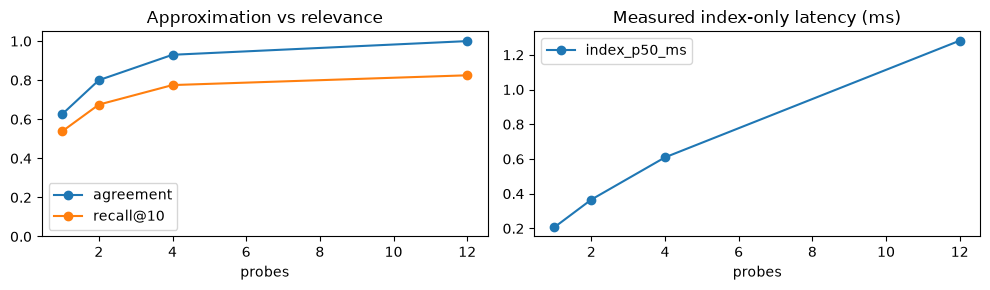

Constructed speedup: 1.12


In [4]:
fig,axes=plt.subplots(1,2,figsize=(10,3))
sweep[['agreement','recall@10']].plot(marker='o',ax=axes[0],ylim=(0,1.05),title='Approximation vs relevance')
sweep[['index_p50_ms']].plot(marker='o',ax=axes[1],title='Measured index-only latency (ms)')
plt.tight_layout();plt.show()
fixed_ms=12.; original_index_ms=2.; improved_index_ms=.5
print('Constructed speedup:',(fixed_ms+original_index_ms)/(fixed_ms+improved_index_ms))

## 4. 全簇等价是可执行约束

当探测所有簇时，候选应覆盖全语料，排序应与精确相同；该检查能抓住内部编号偏移、候选丢失或并列规则不一致。单看平均NDCG相同不足以保证逐文档相同。

In [5]:
for q,v in zip(qids[:8],query_vectors(qids[:8])):
    ids,count=partition_retrieval(ctx['vectors'],v,centers,assignment,probes=12,k=10)
    exact=topk(np.r_[-np.inf,ctx['vectors']@v],10)
    assert (ids+1).tolist()==exact and count==5183
print('8 queries: full-probe document-level equivalence verified')

/Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


8 queries: full-probe document-level equivalence verified


**练习**：固定probes=2，仅改变聚类种子，观察候选数与qrels Recall波动。不能把最好的测试种子作为最终成绩；若要选索引参数，应另用训练/选择查询，再保留独立审计。下一章把词法与语义两个召回通道联合起来。